# Trabalho Prático — preparação dos dados (etapas 1 a 3)

**Estado:** desenvolvimento com 1% dos livros; não há TF-IDF, PCA/SVD ou agrupamento nesta versão.

**Integrantes:** João Henrique Valbusa Lima - 2023100583 - joao.h.lima@edu.ufes.br

Objetivo futuro: agrupar livros pela descrição e investigar a distribuição de gêneros nos grupos. `genre`, título, autor e atributos numéricos não entram na preparação dos textos para o modelo.

## Configuração e reprodução

Selecionar o ambiente `CD/.venv`. Se necessário, instalar `python -m pip install -r requirements.txt` a partir de `trabalhoPratico`. Executar todas as células na ordem. A lista de stopwords está incluída em `recursos`, sem downloads durante a execução. A fração e a semente são configuráveis; o padrão desta execução é 1% e 42.

In [ ]:
from pathlib import Path
import hashlib
import html
import importlib.metadata
import json
import math
import platform
import re
import sys
import time
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from langdetect import DetectorFactory, detect, LangDetectException
from nltk.stem import PorterStemmer

INICIO = time.perf_counter()
FRACAO = 0.01
SEMENTE = 67
APLICAR_STEMMING = False
assert 0 < FRACAO <= 1

candidatos = [Path.cwd(), Path.cwd() / 'trabalhoPratico',
              Path.cwd() / 'periodo-8/CD/trabalhoPratico']
BASE = next((p for p in candidatos if (p / 'goodreads_books.csv').is_file()), None)
if BASE is None:
    raise FileNotFoundError('Abra o notebook em trabalhoPratico, CD ou na raiz de UFES.')
SAIDA = BASE / 'resultados' / f'amostra_{FRACAO * 100:g}pct_seed{SEMENTE}'
SAIDA.mkdir(parents=True, exist_ok=True)
ORIGEM = BASE / 'goodreads_books.csv'

def sha256(caminho):
    return hashlib.sha256(caminho.read_bytes()).hexdigest()

HASH_ORIGINAL = sha256(ORIGEM)
ambiente = {
    'python': sys.version, 'executable': sys.executable,
    'sistema': platform.platform(), 'arquitetura': platform.machine(),
    'processador': platform.processor(),
    'versoes': {x: importlib.metadata.version(x)
                for x in ['pandas', 'numpy', 'matplotlib', 'nltk', 'langdetect', 'nbformat', 'nbclient']},
}
# /proc registra o ambiente de execução; pode representar uma VM/contêiner.
if Path('/proc/cpuinfo').exists():
    ambiente['cpu'] = next((l.split(':', 1)[1].strip() for l in
                             Path('/proc/cpuinfo').read_text().splitlines()
                             if l.startswith('model name')), 'não informado')
if Path('/proc/meminfo').exists():
    ambiente['memoria_total_kib'] = int(Path('/proc/meminfo').read_text().split('MemTotal:')[1].split()[0])
ambiente['observacao'] = 'Recursos visíveis ao sistema; limites do contêiner podem ser menores.'
print(f'Fração: {FRACAO:.0%}; semente: {SEMENTE}; stemming: {APLICAR_STEMMING}')
print('Python:', sys.executable)
print('Arquivos de saída:', SAIDA.relative_to(BASE))

Fração: 1%; semente: 42; stemming: False
Python: /home/chefe/workspace/UFES/periodo-8/CD/.venv/bin/python
Arquivos de saída: resultados/amostra_1pct_seed42


## Etapa 1 — inspeção do conjunto completo

Estudar `../aulas/aula_pandas.ipynb`: informações do DataFrame, descrição básica, filtros e agregações.

A inspeção usa o CSV completo, que é pequeno em disco. A amostragem limita o processamento textual posterior. Não preencher ano/páginas ausentes: esses atributos não serão usados no fluxo obrigatório. Descrições repetidas são sinalizadas e mantidas: livros distintos podem compartilhar sinopses, e removê-los exige análise específica. IDs repetidos impedem continuar sem revisão.

In [2]:
dados = pd.read_csv(ORIGEM)
colunas = ['book_id', 'title', 'author', 'description', 'genre',
           'publication_year', 'average_rating', 'ratings_count', 'num_pages']
assert list(dados.columns) == colunas, 'Revisar alteração no esquema do CSV.'
assert dados['book_id'].notna().all() and dados['book_id'].is_unique

perfil = pd.DataFrame({
    'tipo': dados.dtypes.astype(str),
    'ausentes': dados.isna().sum(),
    'strings_vazias': [int(dados[c].fillna('').astype(str).str.strip().eq('').sum())
                      if pd.api.types.is_string_dtype(dados[c]) else 0 for c in dados],
    'valores_distintos': dados.nunique(dropna=True),
})
disponivel = dados['description'].fillna('').str.strip().ne('')
elegiveis = dados.loc[disponivel].copy()
auditoria = {
    'linhas': len(dados), 'colunas': len(dados.columns),
    'linhas_inteiramente_duplicadas': int(dados.duplicated().sum()),
    'ids_repetidos': int(dados['book_id'].duplicated().sum()),
    'descricoes_repetidas_apos_primeira': int(dados['description'].duplicated().sum()),
    'descricoes_ausentes_ou_em_branco': int((~disponivel).sum()),
    'linhas_elegiveis': len(elegiveis),
    'tamanho_csv_bytes': ORIGEM.stat().st_size,
    'memoria_dataframe_bytes': int(dados.memory_usage(deep=True).sum()),
}
print(json.dumps(auditoria, ensure_ascii=False, indent=2))
display(perfil)
display(dados.select_dtypes(include='number').describe().round(2))
display(dados['description'].str.len().describe().rename('caracteres_por_descricao'))
perfil.to_csv(SAIDA / 'perfil_colunas.csv', index_label='coluna')

{
  "linhas": 25000,
  "colunas": 9,
  "linhas_inteiramente_duplicadas": 0,
  "ids_repetidos": 0,
  "descricoes_repetidas_apos_primeira": 237,
  "descricoes_ausentes_ou_em_branco": 0,
  "linhas_elegiveis": 25000,
  "tamanho_csv_bytes": 23456989,
  "memoria_dataframe_bytes": 28569846
}


,tipo,ausentes,strings_vazias,valores_distintos
book_id,int64,0,0,25000
title,str,0,0,24244
author,str,0,0,17509
description,str,0,0,24763
genre,str,0,0,3877
publication_year,float64,5069,0,116
average_rating,float64,0,0,279
ratings_count,int64,0,0,2264
num_pages,float64,7273,0,856


,book_id,publication_year,average_rating,ratings_count,num_pages
count,25000.00,19931.00,25000.00,25000.00,17727.00
mean,14746746.35,2008.55,3.87,700.04,251.49
std,10710700.69,131.22,0.41,14432.16,183.32
min,160.00,13.00,0.00,0.00,0.00
25%,3842592.25,2006.00,3.65,10.00,131.00
50%,15706952.50,2011.00,3.89,36.00,240.00
75%,23386488.00,2014.00,4.13,138.00,338.00
max,36447466.00,20136.00,5.00,2028299.00,4193.00


count    25000.000000
mean       830.876680
std        531.725617
min        100.000000
25%        475.000000
50%        753.000000
75%       1056.000000
max       9398.000000
Name: caracteres_por_descricao, dtype: float64

## Etapa 2 — amostra aleatória reproduzível

Estudar `../aulas/aula.ipynb` (amostragem e Lei dos Grandes Números) e o acesso às linhas em Pandas.

Amostragem aleatória simples, sem reposição, das linhas com descrição não vazia, com semente fixa. O tamanho usa arredondamento para cima; com 25.000 elegíveis, 1% resulta em 250 livros. Não há estratificação por gênero. Os IDs permitem reproduzir exatamente a seleção mesmo após mudanças de ordenação, desde que o conteúdo da base seja o mesmo.

O arquivo preexistente `dataset_1_perct.csv` é preservado. Os artefatos desta execução ficam em uma pasta própria. Esta amostra serve para desenvolver e verificar o fluxo, sem sustentar conclusões finais sobre os gêneros.

In [3]:
tamanho = min(len(elegiveis), math.ceil(len(elegiveis) * FRACAO))
assert tamanho > 0
amostra = elegiveis.sample(n=tamanho, replace=False, random_state=SEMENTE).copy()
assert len(amostra) == tamanho and amostra['book_id'].is_unique
assert set(amostra['book_id']).issubset(set(dados['book_id']))
amostra.to_csv(SAIDA / 'amostra_original.csv', index=False)
amostra[['book_id']].to_csv(SAIDA / 'ids_amostra.csv', index=False)
print(f'Selecionados {len(amostra)} de {len(elegiveis)} elegíveis ({len(amostra)/len(elegiveis):.2%}).')
display(amostra[['book_id', 'description']].head())

Selecionados 250 de 25000 elegíveis (1.00%).


,book_id,description
6868,18266202,When sweet revenge turns sour... Book two of a...
24016,2577666,In twelve beautifully articulated stories Maxi...
9668,7123056,"This is the story of when I was a boy, almost ..."
13640,25245072,Together for the first time... Kent and Elly's...
14018,7090315,Three signs that something is very different w...


## Etapa 3 — idioma e pré-processamento

Estudar `../aulas/aula_dados_textuais.ipynb`, seção “Limpeza e pré-processamento”.

Primeiro, identificar exploratoriamente o idioma das descrições selecionadas com `langdetect` e semente fixa. A detecção é uma heurística, especialmente frágil em textos curtos; ela não equivale a uma validação humana. Textos detectados como diferentes de inglês são sinalizados para revisão e mantidos. Neles não se aplicam stopwords inglesas nem stemming inglês.

Fluxo: decodificar entidades HTML; normalizar Unicode com NFKC e apóstrofos; remover URLs e tags HTML simples; converter para minúsculas; tokenizar palavras Unicode com apóstrofo interno; remover stopwords inglesas somente nos textos detectados como ingleses. Preservar `no`, `nor` e `not` para não apagar negações. A remoção de símbolos descarta números; revisar essa escolha em obras cuja sinopse dependa de datas ou códigos.

**Baseline sem stemming:** manter palavras inteiras facilita a inspeção e evita confluir palavras indevidamente. A opção `APLICAR_STEMMING` permite experimentar Porter depois; lematização não é aplicada. Não remover acentos: isso preserva a escrita de nomes e de eventuais textos em outros idiomas. Nenhuma regra consulta gênero, título ou autor.

As stopwords são uma cópia da lista inglesa distribuída pelo corpus NLTK (`nltk_data/corpora/stopwords`), preservada em `recursos/stopwords_english.txt`; seu hash entra no manifesto.

In [4]:
DetectorFactory.seed = SEMENTE

def identificar_idioma(texto):
    try:
        return detect(texto)
    except LangDetectException:
        return 'indeterminado'

STOPWORDS_ARQUIVO = BASE / 'recursos/stopwords_english.txt'
stopwords_ingles = set(STOPWORDS_ARQUIVO.read_text().splitlines()) - {'no', 'nor', 'not'}
porter = PorterStemmer()
padrao_palavras = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)?", re.UNICODE)

def preprocessar(texto, idioma):
    texto = unicodedata.normalize('NFKC', html.unescape(texto))
    texto = texto.replace('’', "'").replace('‘', "'")
    texto = re.sub(r'https?://\S+|www\.\S+', ' ', texto)
    texto = re.sub(r'</?[A-Za-z][^>]*>', ' ', texto)
    tokens = padrao_palavras.findall(texto.lower())
    total_antes = len(tokens)
    if idioma == 'en':
        tokens = [token for token in tokens if token not in stopwords_ingles]
        if APLICAR_STEMMING:
            tokens = [porter.stem(token) for token in tokens]
    return ' '.join(tokens), total_antes, len(tokens)

textos = amostra[['book_id', 'description']].copy().reset_index(drop=True)
textos = textos.rename(columns={'description': 'description_original'})
textos['idioma_detectado'] = textos['description_original'].map(identificar_idioma)
resultado = [preprocessar(t, idioma) for t, idioma in
             zip(textos['description_original'], textos['idioma_detectado'])]
textos[['description_clean', 'tokens_antes', 'tokens_depois']] = pd.DataFrame(resultado)
textos['revisar_idioma'] = textos['idioma_detectado'].ne('en')
textos['texto_vazio_apos_limpeza'] = textos['description_clean'].str.strip().eq('')
print('Idiomas detectados (sujeitos a erro):')
display(textos['idioma_detectado'].value_counts().rename_axis('idioma').to_frame('livros'))
print('Textos vazios após limpeza:', int(textos['texto_vazio_apos_limpeza'].sum()))
display(textos[['tokens_antes', 'tokens_depois']].describe().round(2))
display(textos[['book_id', 'description_original', 'description_clean']].head())
display(textos.loc[textos['revisar_idioma'], ['book_id', 'idioma_detectado', 'description_original']])

Idiomas detectados (sujeitos a erro):


,livros
idioma,
en,246
es,2
pt,1
sl,1


Textos vazios após limpeza: 0


,tokens_antes,tokens_depois
count,250.00,250.00
mean,138.64,78.37
std,97.04,53.07
min,16.00,10.00
25%,72.25,44.00
50%,124.00,73.00
75%,183.00,101.75
max,1018.00,547.00


,book_id,description_original,description_clean
0,18266202,When sweet revenge turns sour... Book two of a...,sweet revenge turns sour book two trilogy new ...
1,2577666,In twelve beautifully articulated stories Maxi...,twelve beautifully articulated stories maxine ...
2,7123056,"This is the story of when I was a boy, almost ...",story boy almost years ago fire engines pulled...
3,25245072,Together for the first time... Kent and Elly's...,together first time kent elly's story combined...
4,7090315,Three signs that something is very different w...,three signs something different mew man sleeps...


,book_id,idioma_detectado,description_original
9,8701925,es,Relaciones escandalosas reune tres de los rela...
22,1306218,pt,Num vasto deserto do Novo Mexico esconde-se um...
203,11250084,sl,Na vrhuncu Odprtega teniskega prvenstva ZDA v ...
216,22082664,es,"Una competencia excepcional, en la que el prem..."


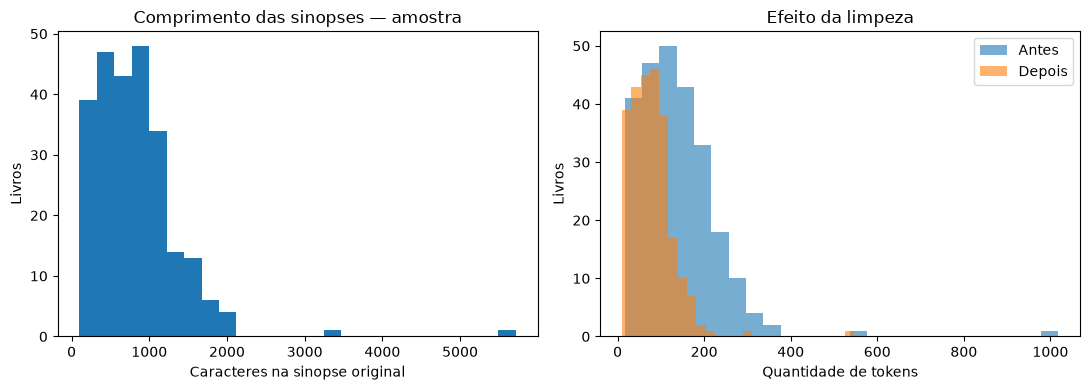

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].hist(textos['description_original'].str.len(), bins=25)
eixos[0].set(xlabel='Caracteres na sinopse original', ylabel='Livros', title='Comprimento das sinopses — amostra')
eixos[1].hist(textos['tokens_antes'], bins=25, alpha=0.6, label='Antes')
eixos[1].hist(textos['tokens_depois'], bins=25, alpha=0.6, label='Depois')
eixos[1].set(xlabel='Quantidade de tokens', ylabel='Livros', title='Efeito da limpeza')
eixos[1].legend()
fig.tight_layout()
fig.savefig(SAIDA / 'comprimento_descricoes.png', dpi=140)
plt.show()

## Verificações, exportação e limites

Salvar textos processados sem gêneros nem outros atributos preditivos. Preservar a descrição original, IDs, contagens e flags. Descrições que se tornem vazias ficam registradas para auditoria e são excluídas apenas do arquivo de entrada textual da próxima etapa.

As flags de idioma precisam de revisão antes de usar stopwords inglesas indiscriminadamente. Descrições repetidas continuam presentes e devem ser consideradas na interpretação futura. Nenhum resultado de desempenho de modelo é produzido aqui. Para ampliar a base, mudar `FRACAO` e executar novamente; revisar idiomas, tempos e memória na nova escala.

In [6]:
assert len(textos) == tamanho
assert textos['book_id'].tolist() == amostra['book_id'].tolist()
assert textos['description_original'].tolist() == amostra['description'].tolist()
assert 'genre' not in textos.columns
assert textos['tokens_depois'].le(textos['tokens_antes']).all()
assert sha256(ORIGEM) == HASH_ORIGINAL, 'O CSV original foi alterado.'

textos.to_csv(SAIDA / 'descricoes_preprocessadas.csv', index=False)
entrada = textos.loc[~textos['texto_vazio_apos_limpeza'], ['book_id', 'description_clean']]
entrada.to_csv(SAIDA / 'entrada_textual.csv', index=False)
textos.loc[textos['revisar_idioma']].to_csv(SAIDA / 'revisao_idioma.csv', index=False)

manifesto = {
    'escopo': 'Etapas 1 a 3: inspeção, amostragem e pré-processamento; sem modelos.',
    'origem': {'arquivo': ORIGEM.name, 'sha256': HASH_ORIGINAL},
    'auditoria': auditoria,
    'amostragem': {'metodo': 'aleatória simples sem reposição, pandas.DataFrame.sample',
                   'fracao_solicitada': FRACAO, 'semente': SEMENTE,
                   'tamanho': tamanho, 'base': 'linhas com descrição não vazia',
                   'ids_na_ordem': textos['book_id'].tolist()},
    'preprocessamento': {
        'unicode': 'NFKC', 'minusculas': True, 'remover_urls': True,
        'remover_tags_html_simples': True, 'remover_numeros': True,
        'stemming_ingles': APLICAR_STEMMING, 'lematizacao': False,
        'remover_acentos': False, 'negacoes_preservadas': ['no', 'nor', 'not'],
        'stopwords_origem': 'NLTK data, corpora/stopwords, english',
        'stopwords_sha256': sha256(STOPWORDS_ARQUIVO),
        'stopwords_aplicadas_somente_em': 'en segundo langdetect',
    },
    'resultados': {
        'idiomas_detectados': {str(k): int(v) for k,v in textos['idioma_detectado'].value_counts().items()},
        'textos_vazios_apos_limpeza': int(textos['texto_vazio_apos_limpeza'].sum()),
        'textos_para_proxima_etapa': len(entrada),
        'descricoes_limpas_repetidas_apos_primeira': int(entrada['description_clean'].duplicated().sum()),
        'tokens_antes': int(textos['tokens_antes'].sum()),
        'tokens_depois': int(textos['tokens_depois'].sum()),
    },
    'ambiente': ambiente,
    'tempo_total_segundos': round(time.perf_counter() - INICIO, 3),
    'colaboracao': 'Preparação de código e texto com auxílio do Codex (OpenAI); revisar antes da entrega.',
}
manifesto['arquivos_sha256'] = {p.name: sha256(p) for p in sorted(SAIDA.iterdir())
                                if p.suffix in {'.csv', '.png'}}
(SAIDA / 'manifesto.json').write_text(json.dumps(manifesto, ensure_ascii=False, indent=2) + '\n')
print(json.dumps(manifesto['resultados'], ensure_ascii=False, indent=2))
print('Verificações de integridade aprovadas. CSV original preservado.')
print('Tempo total (s):', manifesto['tempo_total_segundos'])

{
  "idiomas_detectados": {
    "en": 246,
    "es": 2,
    "pt": 1,
    "sl": 1
  },
  "textos_vazios_apos_limpeza": 0,
  "textos_para_proxima_etapa": 250,
  "descricoes_limpas_repetidas_apos_primeira": 0,
  "tokens_antes": 34661,
  "tokens_depois": 19593
}
Verificações de integridade aprovadas. CSV original preservado.
Tempo total (s): 1.995


## Materiais de apoio e próximos passos

- Enunciado local: `Especificação_2026_2.ipynb` (metodologia, observações importantes e entrega).
- Notebooks locais: `../aulas/aula_pandas.ipynb`, `../aulas/aula.ipynb`, `../aulas/aula_dados_textuais.ipynb`.
- Stopwords: [NLTK data — corpus](https://github.com/nltk/nltk_data/tree/gh-pages/packages/corpora).
- [NLTK PorterStemmer](https://www.nltk.org/api/nltk.stem.porter.html).
- [langdetect](https://pypi.org/project/langdetect/) — identificação exploratória de idioma; não garante classificação correta.

Próxima etapa autorizável separadamente: construir TF-IDF. Depois, redução dimensional, dois algoritmos de agrupamento, validação e análise dos gêneros. Antes de ampliar, revisar os textos sinalizados por idioma e conferir manualmente os exemplos de limpeza.